# Лабораторная работа №3. Обеспечение качества данных

**Выполнили:** Марюшкина Софья и Чуева Арина, поток 1.3.

## 2. Цель и задачи лабораторной работы

**Цель:** исследовать исходную таблицу вакансий и повысить пригодность данных для анализа, стандартизировав местоположение, зарплату и вид занятости.

**Задачи:**

1. Описать поля, пропуски, константные столбцы, пересечения значений и дубликаты.
2. Найти форматы `location`, выделить город, штат и почтовый индекс; отдельно обработать нераспознанные строки.
3. Найти форматы `salary`, выделить числовые границы и период, сравнить средние и медианы.
4. Исследовать распределения зарплат и оценить неизвестный период по близости к средним с учётом выбросов и неоднозначности.
5. Стандартизировать `job_type`, выделить полноту и тип занятости, заполнить отсутствующие части по условию задания.
6. Оценить результат преобразований, сохранить обработанные данные и сформулировать выводы.

## 3. Описание входных данных

Использован файл `monster_com_job_sample.csv`: 22 000 записей о вакансиях и 14 столбцов.

| Поле | Содержание |
|---|---|
| `country`, `country_code` | Название и код страны |
| `date_added` | Дата размещения |
| `has_expired` | Статус объявления |
| `job_board` | Площадка размещения |
| `job_description`, `job_title` | Описание и название вакансии |
| `job_type` | Вид занятости |
| `location` | Местоположение |
| `organization` | Организация |
| `page_url` | Адрес объявления |
| `salary` | Зарплата |
| `sector` | Сфера деятельности |
| `uniq_id` | Идентификатор записи |

Пустые и пробельные строки приняты за пропуски. Новые признаки добавлены к исходным полям. Почтовые индексы сохранены в строковом формате.

## 4. Описание этапов выполнения работы

### 4.1. Подготовка окружения и загрузка

Для обработки использованы Python, pandas, NumPy и регулярные выражения, для графиков — matplotlib. Данные загружены из CSV-файла в DataFrame.

In [ ]:
import importlib.util
import subprocess
import sys

required = {"pandas": "pandas>=2.2,<3", "numpy": "numpy>=1.26,<3",
            "matplotlib": "matplotlib>=3.9,<4", "gdown": "gdown>=5,<6"}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import re
import os
import hashlib
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
Path("data/matplotlib").mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(Path("data/matplotlib").resolve()))
import matplotlib
from matplotlib import pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", 12)
plt.rcParams.update({"figure.figsize": (10, 4.8), "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "figure.dpi": 110})

DATA = Path("data/monster_com_job_sample.csv")
DATA.parent.mkdir(exist_ok=True)
EXPECTED_SHA256 = "6bcb47dfc18bfb032a1b0a0cbd34314cb838c0c1e4c287f9336332aff3ebc5bb"
if not DATA.exists():
    import gdown
    downloaded = gdown.download(id="1s_X49sgW_HQQALThvElR8g4_Mp-VaWEo",
                                output=str(DATA), quiet=False)
    if not downloaded:
        raise RuntimeError("Не удалось загрузить файл data/monster_com_job_sample.csv.")
actual_sha256 = hashlib.sha256(DATA.read_bytes()).hexdigest()
if actual_sha256 != EXPECTED_SHA256:
    raise ValueError("CSV отличается от версии отчёта или скачан не полностью. "
                     "Проверьте источник; не меняйте SHA256 без повторного анализа.")
raw = pd.read_csv(DATA, dtype="string", keep_default_na=False)
df = raw.replace(r"^\s*$", pd.NA, regex=True)
assert df.shape == (22000, 14)
display(df.sample(5, random_state=13))

,country,country_code,date_added,has_expired,job_board,job_description,...,location,organization,page_url,salary,sector,uniq_id
927,United States of America,US,<NA>,No,jobs.monster.com,"Schedule: Full-time, ContractLocation: Chantilly, VATravel Required: Less than 10%Clearance: Gov...",...,"Schedule: Full-time, ContractLocation: Chantilly, VATravel Required: Less than 10%Clearance: Gov...",<NA>,http://jobview.monster.com/case-reviewer-case-scoper-job-chantilly-va-us-168908274.aspx?mescoid=...,<NA>,<NA>,02020fe13ed01d855e6024bebeb670fd
20314,United States of America,US,<NA>,No,jobs.monster.com,"ReceptionistReceptionist position open in Houston, TX for a leading commercial banking instituti...",...,"Houston, TX",Banking,http://jobview.monster.com/receptionist-job-houston-tx-us-169204799.aspx?mescoid=4301136002005&j...,16.00 - 20.00 /hour,Administrative/Clerical,b6c1f959f28c2ba0d531daac4cac8377
6660,United States of America,US,<NA>,No,jobs.monster.com,12B Combat Engineer - Construction and Engineering Specialist Job DescriptionWe're looking for t...,...,"Rolla, MO 65401",<NA>,http://jobview.monster.com/12b-combat-engineer-construction-engineering-specialist-job-rolla-mo-...,<NA>,Entry Level,ef76a86fb5b830820f509d1bc963b5aa
1011,United States of America,US,<NA>,No,jobs.monster.com,Client Manager-Property & Casualty at Willis Towers Watson Date Posted: 5/27/2016 Employee Type...,...,"Dallas, TX",Other/Not Classified,http://jobview.monster.com/client-manager-property-casualty-at-willis-towers-watson-job-dallas-t...,<NA>,Experienced (Non-Manager),abcc10c445fdb8829c1d692c34fbee9e
5419,United States of America,US,<NA>,No,jobs.monster.com,Compliance Review Examiner Responsibilities: Develop compliance review programs for specific bus...,...,"New York, NY",Staffing/Employment Agencies,http://jobview.monster.com/Compliance-Review-Examiner-Job-New-York-NY-US-162554271.aspx?mescoid=...,<NA>,Experienced (Non-Manager),66865b7f30dfd1ac09ac8dcb968b342e


### 4.2. Первичное понимание данных

Выведены случайные строки, определены типы данных и основные проблемы каждого столбца.

In [ ]:
problems = {
    "country": "Константа: United States of America; не разделяет вакансии внутри выборки.",
    "country_code": "Константа US; повторяет информацию country.",
    "date_added": "Почти всё пропущено; непустые даты записаны текстом M/D/YYYY.",
    "has_expired": "Константа No; исторический флаг, актуальность сейчас не проверена.",
    "job_board": "Константа jobs.monster.com.",
    "job_description": "Длинный свободный текст, повторы; местами следы повреждённой кодировки.",
    "job_title": "Названия, местоположение и служебный текст смешаны; есть повторы.",
    "job_type": "Пропуски, разные разделители и пробелы, неполные и нестандартные категории.",
    "location": "Город/штат/ZIP в разных сочетаниях, слитные записи, контакты и описания вакансий.",
    "organization": "Пропуски; часто отрасль (Healthcare Services), а не название компании.",
    "page_url": "Уникальные URL; разные ссылки не гарантируют разные вакансии.",
    "salary": "Большинство пропущено; интервалы, одна сумма, разные периоды, бонусы и текст.",
    "sector": "Пропуски; смешаны отрасль/функция и уровень должности (Entry Level и др.).",
    "uniq_id": "Уникален как ID записи; не исключает повторов содержания."}
profile = pd.DataFrame({"Тип данных": df.dtypes.astype(str),
                        "Уникальных непустых": df.nunique(),
                        "Проблемы": pd.Series(problems)})
display(profile)

,Тип данных,Уникальных непустых,Проблемы
country,string,1,Константа: United States of America; не разделяет вакансии внутри выборки.
country_code,string,1,Константа US; повторяет информацию country.
date_added,string,78,Почти всё пропущено; непустые даты записаны текстом M/D/YYYY.
has_expired,string,1,"Константа No; исторический флаг, актуальность сейчас не проверена."
job_board,string,1,Константа jobs.monster.com.
job_description,string,18744,"Длинный свободный текст, повторы; местами следы повреждённой кодировки."
job_title,string,18759,"Названия, местоположение и служебный текст смешаны; есть повторы."
job_type,string,39,"Пропуски, разные разделители и пробелы, неполные и нестандартные категории."
location,string,8423,"Город/штат/ZIP в разных сочетаниях, слитные записи, контакты и описания вакансий."
organization,string,738,"Пропуски; часто отрасль (Healthcare Services), а не название компании."


### 4.3. Оценка пустых ячеек

Подсчитаны пропуски по столбцам и строки, в которых пусты более 75% ячеек. Построена диаграмма и проверен размер таблицы после удаления всех неполных строк.

,Всего ячеек,Пустых,"Пустых, %"
country,22000,0,0.00
country_code,22000,0,0.00
date_added,22000,21878,99.45
has_expired,22000,0,0.00
job_board,22000,0,0.00
job_description,22000,0,0.00
job_title,22000,0,0.00
job_type,22000,1628,7.40
location,22000,0,0.00
organization,22000,6867,31.21


Строк с более 75% пропусков: 0
После dropna: (5, 14); сохранено 0.023% строк
Дополнительные пропуски после учёта пробельных строк: 3


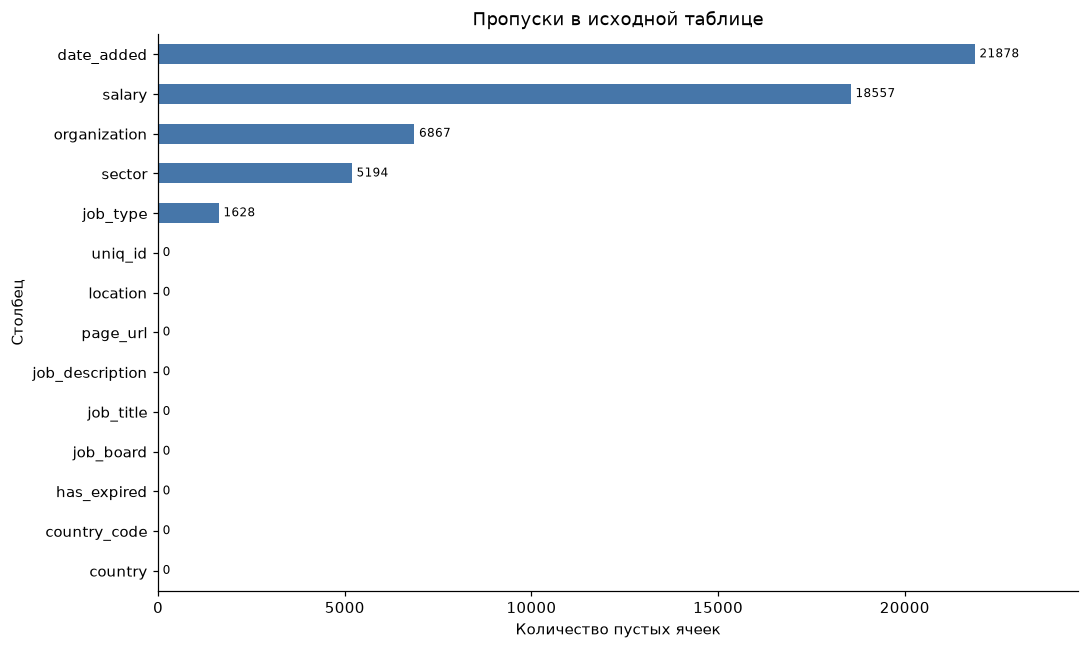

**Вывод:** после удаления строк с пропусками осталось 5 из 22 000 вакансий. Для дальнейшей обработки все строки сохранены.

In [ ]:
missing_table = pd.DataFrame({"Всего ячеек": len(df), "Пустых": df.isna().sum()})
missing_table["Пустых, %"] = (100 * missing_table["Пустых"] / len(df)).round(2)
display(missing_table)
mostly_empty = df.isna().mean(axis=1).gt(0.75)
complete = df.dropna()
print("Строк с более 75% пропусков:", int(mostly_empty.sum()))
print(f"После dropna: {complete.shape}; сохранено {len(complete)/len(df):.3%} строк")
print("Дополнительные пропуски после учёта пробельных строк:",
      int(df.isna().sum().sum() - raw.eq("").sum().sum()))
ax = missing_table["Пустых"].sort_values().plot.barh(color="#4676a9", figsize=(10, 6))
ax.set(xlabel="Количество пустых ячеек", ylabel="Столбец", title="Пропуски в исходной таблице")
ax.bar_label(ax.containers[0], padding=3, fontsize=8)
ax.set_xlim(0, len(df) * 1.12)
plt.tight_layout()
plt.show()
display(Markdown('**Вывод:** после удаления строк с пропусками осталось 5 из 22 000 вакансий. Для дальнейшей обработки все строки сохранены.'))

### 4.4. Константы, пересечения и соответствие названиям

Найдены столбцы с одним значением и точные совпадения значений между разными столбцами. Содержимое полей сопоставлено с их названиями.

In [ ]:
constants = [c for c in df if df[c].nunique(dropna=False) == 1]
display(pd.DataFrame({"Столбец": constants,
                      "Единственное значение": [df[c].iloc[0] for c in constants]}))
value_sets = {c: set(df[c].dropna().str.strip()) for c in df}
overlaps = []
for left, right in combinations(df.columns, 2):
    common = value_sets[left] & value_sets[right]
    if common:
        overlaps.append({"Столбец 1": left, "Столбец 2": right,
                         "Общих значений": len(common),
                         "Примеры": "; ".join(str(x)[:70] for x in sorted(common)[:3])})
display(pd.DataFrame(overlaps))
for c in ["organization", "sector"]:
    print(f"Частые значения {c}:")
    display(df[c].value_counts().head(8).rename("Количество").to_frame())
contaminated_locations = df.location.str.len().gt(150).fillna(False)
display(df.loc[contaminated_locations, ["uniq_id", "location"]].head(3))
display(Markdown('**Вывод:** найдены четыре константных поля. В `organization` часто указана отрасль, в `sector` — функция или уровень должности, в `location` — посторонний текст.'))

,Столбец,Единственное значение
0,country,United States of America
1,country_code,US
2,has_expired,No
3,job_board,jobs.monster.com


,Столбец 1,Столбец 2,Общих значений,Примеры
0,job_description,job_title,1,Please apply only if you are qualified.
1,job_description,location,849,"""Summer Walk In Wednesdays"" July & August!! - Kindred Hospital Chattan; $5,000 Dollar Sign on Bo..."
2,job_title,location,12,Business Analyst; Field Service Technician; Job Details
3,job_type,location,1,Full Time Employee
4,job_type,organization,1,Full Time Employee
5,location,organization,126,"A & E Network; Albany, NY; Allentown, PA"
6,organization,sector,2,Electrical/Electronics EngineeringIndustrial/Manufacturing Engineering; Retail


Частые значения organization:


,Количество
organization,
Healthcare Services,1919
All,1158
Retail,1081
Other/Not Classified,1048
Manufacturing - Other,885
Computer/IT Services,822
Legal Services,466
Business Services - Other,410


Частые значения sector:


,Количество
sector,
Experienced (Non-Manager),4594
Medical/Health,1254
Entry Level,1172
Sales/Retail/Business Development,938
Manager (Manager/Supervisor of Staff),900
IT/Software Development,861
Project/Program Management,790
Accounting/Finance/Insurance,742


,uniq_id,location
2,839106b353877fa3d896ffb9c1fe01c0,"DePuy Synthes Companies is a member of Johnson & Johnson's Family of Companies, and is recruitin..."
45,562eeb3d055f4483cf7f1750a4b66f61,Respiratory Therapist PRN Nights - Kindred Hospital Medical Center ( Job Number: 266123 ) Descri...
105,bc86f3a00090a77ba5e4fcf10537c2cb,Registered Nurse ICU Full Time Days - Kindred Hospital Town and Country ( Job Number: 259725 ) D...


**Вывод:** найдены четыре константных поля. В `organization` часто указана отрасль, в `sector` — функция или уровень должности, в `location` — посторонний текст.

### 4.5. Дублирование данных

Проверена уникальность `uniq_id` и остальных столбцов. После исключения уникальных полей найдены строки с одинаковым содержанием.

In [ ]:
unique_columns = [c for c in df if df[c].notna().all() and df[c].is_unique]
content_columns = [c for c in df if c not in unique_columns]
duplicate_extra = df.duplicated(subset=content_columns)
duplicate_all = df.duplicated(subset=content_columns, keep=False)
duplicate_groups = df.loc[duplicate_all, content_columns].drop_duplicates().shape[0]
print("uniq_id без пропусков:", bool(df.uniq_id.notna().all()), "уникален:", df.uniq_id.is_unique)
print("Полностью уникальные столбцы:", unique_columns)
print("Точных дубликатов по всем столбцам:", int(df.duplicated().sum()))
print("Избыточных строк без уникальных полей:", int(duplicate_extra.sum()))
print("Строк в повторяющихся группах:", int(duplicate_all.sum()), "групп:", duplicate_groups)
display(df.loc[duplicate_all, ["uniq_id", "job_title", "location", "page_url"]].head(8))
display(Markdown('**Вывод:** ID и URL уникальны, но содержимое части записей повторяется. Такие строки отмечены отдельным признаком.'))

uniq_id без пропусков: True уникален: True
Полностью уникальные столбцы: ['page_url', 'uniq_id']


Точных дубликатов по всем столбцам: 0
Избыточных строк без уникальных полей: 1168
Строк в повторяющихся группах: 2078 групп: 910


,uniq_id,job_title,location,page_url
17,8d8f39de4a07929a92c2e6dd7a72a0af,Pest Control Technician – Field Service Rep (Entry Level) Job in Denver,"Denver, CO",http://jobview.monster.com/Pest-Control-Technician-%E2%80%93-Field-Service-Rep-Entry-Level-Job-D...
27,de49594f00f4af8c1e0fbffd85120208,Traveling Customer Training Professional Job in Houston,"Houston, TX 77040",http://jobview.monster.com/Traveling-Customer-Training-Professional-Job-Houston-TX-US-167263217....
47,ac2da666b68583ed3c3cc4eaee869eb1,Project Manager ( Z ) Job in Houston,"Houston, TX 77034",http://jobview.monster.com/Project-Manager-1927-2Z-002-Job-Houston-TX-US-167277695.aspx?mescoid=...
56,bcf70c41acf97ac8024c0b38c6fcaf87,CASHIER Job in Houston,"Houston, TX",http://jobview.monster.com/CASHIER-Job-Houston-TX-US-167364608.aspx?mescoid=4100667001001&jobPos...
95,5091d726fbce4a824fe6a1d49458ad4a,Scrum Master Job in Denver,"Denver, CO",http://jobview.monster.com/Scrum-Master-Job-Denver-CO-US-167149009.aspx?mescoid=1500145001001&jo...
96,e52d5e30ecdf97dd64a44f45bfc2032b,Financial Advisor / Financial Sales Representative- Full Time Sales,"Houston, TX",http://jobview.monster.com/Financial-Advisor-Financial-Sales-Representative-Full-Time-Sales-We-T...
114,4b8d7a4b2f7449a446a423a47fab633c,Event Promotions: Marketing / Advertising / Public Relations Job in Houston,"Houston, TX 77057",http://jobview.monster.com/Event-Promotions-Marketing-Advertising-Public-Relations-Job-Houston-T...
165,c76459c6a16425dcf473a4ccf5bdee33,Enrollment Agent I* (-) Job in Denver,"Denver, CO",http://jobview.monster.com/Enrollment-Agent-I-2493-758-Job-Denver-CO-US-167209797.aspx?mescoid=9...


**Вывод:** ID и URL уникальны, но содержимое части записей повторяется. Такие строки отмечены отдельным признаком.

### 4.6. Форматы местоположения (задание 1.1)

С помощью регулярных выражений выделены сочетания города, штата и ZIP. Учтены разные разделители, порядок компонентов и слитные записи. Город без других компонентов проверен по названиям из корректных записей этой же таблицы. Количество форматов, включая нераспознанные, показано на диаграмме.

In [ ]:
STATE_NAMES = {
    "AL": "Alabama", "AK": "Alaska", "AZ": "Arizona", "AR": "Arkansas", "CA": "California",
    "CO": "Colorado", "CT": "Connecticut", "DE": "Delaware", "DC": "District of Columbia",
    "FL": "Florida", "GA": "Georgia", "HI": "Hawaii", "ID": "Idaho", "IL": "Illinois",
    "IN": "Indiana", "IA": "Iowa", "KS": "Kansas", "KY": "Kentucky", "LA": "Louisiana",
    "ME": "Maine", "MD": "Maryland", "MA": "Massachusetts", "MI": "Michigan", "MN": "Minnesota",
    "MS": "Mississippi", "MO": "Missouri", "MT": "Montana", "NE": "Nebraska", "NV": "Nevada",
    "NH": "New Hampshire", "NJ": "New Jersey", "NM": "New Mexico", "NY": "New York",
    "NC": "North Carolina", "ND": "North Dakota", "OH": "Ohio", "OK": "Oklahoma", "OR": "Oregon",
    "PA": "Pennsylvania", "RI": "Rhode Island", "SC": "South Carolina", "SD": "South Dakota",
    "TN": "Tennessee", "TX": "Texas", "UT": "Utah", "VT": "Vermont", "VA": "Virginia",
    "WA": "Washington", "WV": "West Virginia", "WI": "Wisconsin", "WY": "Wyoming",
    "PR": "Puerto Rico", "GU": "Guam", "VI": "Virgin Islands"}
STATE_ALT = "|".join(STATE_NAMES)
STATE_BY_NAME = {name.casefold(): state for state, name in STATE_NAMES.items()}
STATE_NAME_SUFFIX = re.compile(r",\s*(" + "|".join(re.escape(name) for name in STATE_NAMES.values())
                               + r")(?=\s*(?:\d{5}|US\b|$))", re.I)
ZIP = r"\d{5}(?:-\d{4})?"
CITY = r"[A-Za-z][A-Za-z .’'\-]{0,65}?"
CITY_STATE = re.compile(rf"^(?P<city>{CITY})\s*,?\s+(?P<state>{STATE_ALT})(?:\s+(?P<zip>{ZIP}))?$")
CITY_ZIP = re.compile(rf"^(?P<city>{CITY})\s*,?\s+(?P<zip>{ZIP})$", re.I)
ZIP_CITY = re.compile(rf"^(?P<zip>{ZIP})\s+(?P<city>{CITY})$", re.I)
STATE_ZIP = re.compile(rf"^(?P<state>{STATE_ALT})\s*,?\s*(?P<zip>{ZIP})?$")
STATE_CITY = re.compile(rf"^(?P<state>{STATE_ALT})\s*[,/]\s*(?P<city>{CITY})(?:\s+(?P<zip>{ZIP}))?$")
CITY_ZIP_STATE = re.compile(rf"^(?P<city>{CITY})\s+(?P<zip>{ZIP})\s*,?\s+(?P<state>{STATE_ALT})$")

def compact(value):
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", str(value)).strip()

def reasonable_city(value):
    return (bool(re.fullmatch(CITY, value)) and len(value.split()) <= 6
            and not re.search(r"\b(job|contact|phone|fax|address|title|manager|engineer|specialist|salary|description)\b",
                              value, re.I))

def replace_state_name(text):

    if text.casefold() in STATE_BY_NAME:
        return STATE_BY_NAME[text.casefold()]
    text = STATE_NAME_SUFFIX.sub(lambda m: ", " + STATE_BY_NAME[m[1].casefold()], text)
    return re.sub(r"\s+US$", "", text, flags=re.I).strip()

def location_record(city=None, state=None, zipcode=None, fmt="Не распознан"):
    return {"city": city, "state_code": state.upper() if state else None,
            "postal_code": zipcode, "location_format": fmt}

def parse_location(value, known_cities=frozenset()):
    text = replace_state_name(compact(value))
    if not text:
        return location_record(fmt="Пропуск")
    text = re.sub(r"\s*[,;|/]\s*", ", ", text).strip(" ,")

    text = re.sub(rf"(?<=[a-z])(?P<state>{STATE_ALT})(?=\s*(?:\d{{5}}|$))", r", \g<state>", text)
    m = STATE_ZIP.fullmatch(text)
    if m:
        return location_record(state=m['state'], zipcode=m['zip'], fmt="Штат + ZIP" if m['zip'] else "Штат")
    if re.fullmatch(ZIP, text):
        return location_record(zipcode=text, fmt="ZIP")
    for pattern, fmt in [(CITY_STATE, "Город + штат"), (STATE_CITY, "Город + штат"),
                         (CITY_ZIP_STATE, "Город + штат + ZIP"),
                         (CITY_ZIP, "Город + ZIP"), (ZIP_CITY, "Город + ZIP")]:
        m = pattern.fullmatch(text)
        if m and reasonable_city(m['city'].strip(" ,")):
            parts = m.groupdict()
            city = parts['city'].strip(" ,")
            if len(city) < 2:
                continue
            state, zipcode = parts.get('state'), parts.get('zip')
            if state and zipcode:
                fmt = "Город + штат + ZIP"
            return location_record(city, state, zipcode, fmt)
    if text.casefold() in known_cities:
        return location_record(city=text, fmt="Город (из выборки)")
    return location_record()

,Количество
location_format,
Город + штат + ZIP,11332
Город + штат,7285
Не распознан,2554
Город + ZIP,311
ZIP,254
Штат,230
Штат + ZIP,21
Город (из выборки),13


Проверка суммы форматов: 22000


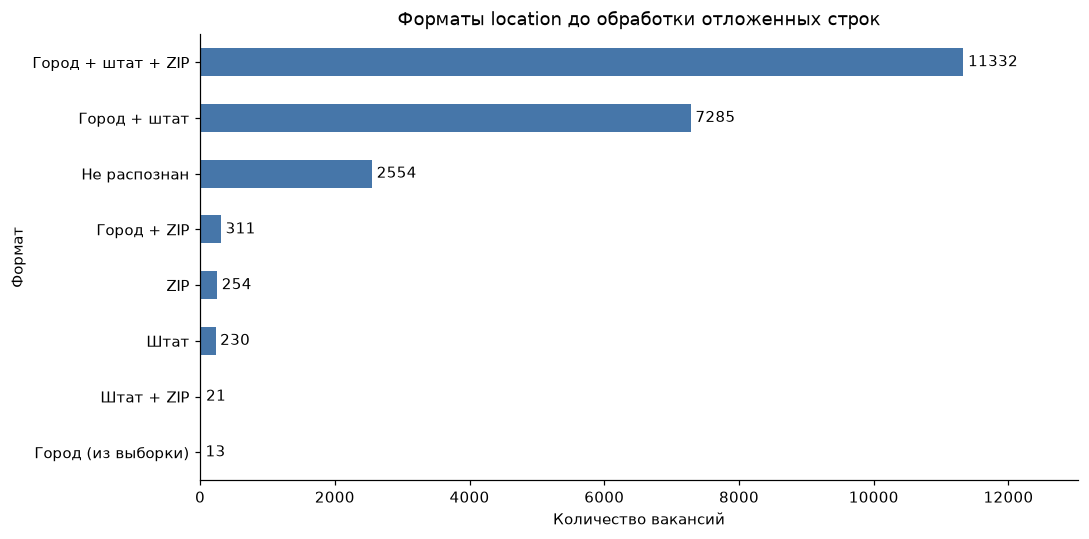

**Вывод:** чаще всего встречается формат «город + штат + ZIP» — 11 332 записи. Не распознано 2 554 записи.

In [ ]:
unique_locations = df.location.dropna().unique()
seed_lookup = {v: parse_location(v) for v in unique_locations}
location_seed = pd.DataFrame(df.location.map(lambda v: seed_lookup.get(v, location_record(fmt="Пропуск"))).tolist(), index=df.index)
known_cities = frozenset(location_seed.loc[location_seed.state_code.notna(), "city"].dropna().str.casefold())
location_lookup = {v: parse_location(v, known_cities) for v in unique_locations}
location_first = pd.DataFrame(df.location.map(lambda v: location_lookup.get(v, location_record(fmt="Пропуск"))).tolist(), index=df.index)
location_counts = location_first.location_format.value_counts()
display(location_counts.rename("Количество").to_frame())
print("Проверка суммы форматов:", int(location_counts.sum()))
ax = location_counts.sort_values().plot.barh(color="#4676a9", figsize=(10, 5))
ax.set(title="Форматы location до обработки отложенных строк", xlabel="Количество вакансий", ylabel="Формат")
ax.bar_label(ax.containers[0], padding=3)
ax.set_xlim(0, location_counts.max() * 1.15)
plt.tight_layout()
plt.show()
display(Markdown('**Вывод:** чаще всего встречается формат «город + штат + ZIP» — 11 332 записи. Не распознано 2 554 записи.'))

### 4.7. Разделение полей и отложенная выборка (задание 1.2)

Местоположение разделено на `city`, `state_code` и `postal_code`. Нераспознанные строки вынесены в отдельную таблицу.

In [ ]:
deferred_mask = location_first.location_format.eq("Не распознан")
deferred_locations = df.loc[deferred_mask].copy()
print("Отложено строк:", len(deferred_locations))
display(pd.concat([df[["location"]], location_first[["city", "state_code", "postal_code"]]], axis=1)
        .loc[~deferred_mask].sample(8, random_state=13))
display(deferred_locations[["uniq_id", "location"]].head(8))

Отложено строк: 2554


,location,city,state_code,postal_code
1375,"Eden Prairie, MN",Eden Prairie,MN,None
19094,"Charlotte, NC 28212",Charlotte,NC,28212
18630,"Newark, OH",Newark,OH,None
8194,"Sioux Falls, SD",Sioux Falls,SD,None
241,"Savannah, GA",Savannah,GA,None
6478,"Richmond, MO 64085",Richmond,MO,64085
5645,"Jacksonville, FL 32258",Jacksonville,FL,32258
2412,"New York, NY 10175",New York,NY,10175


,uniq_id,location
2,839106b353877fa3d896ffb9c1fe01c0,"DePuy Synthes Companies is a member of Johnson & Johnson's Family of Companies, and is recruitin..."
6,455802d725fde67293970ab3953b1d39,Contact name Tony Zerio
29,779bb4c9bf038b7fb775134736d36fd4,"Sr. Process Engineer, Manufacturing"
36,ceb44cca7cd280adcb0c84c20f3c6c21,"RF System Technician, Field Service"
38,4e195c4c6d72e738a1e13aea51005398,Bi-Lingual Editorial Strategist
44,0d9a01619f1ecafbe020974d3b183687,"Bradford, Vt 05033"
45,562eeb3d055f4483cf7f1750a4b66f61,Respiratory Therapist PRN Nights - Kindred Hospital Medical Center ( Job Number: 266123 ) Descri...
72,8db929cfb3be45da28f3fa6127fa3cd1,"""Statewide"", CO"


### 4.8. Обработка отложенных строк (задание 1.3)

Дополнительные компоненты адреса извлечены из фрагментов после `Address`, `Location:` и `Job in`, а также из слитных записей. При неоднозначном результате или отсутствии нужных данных поля оставлены пустыми.

In [ ]:
def recover_location(value, known_cities, pair_pattern):
    text = compact(value)

    stripped = re.sub(r"^Address\s*:?\s*", "", text, flags=re.I)
    if stripped != text:
        direct = parse_location(stripped, known_cities)
        if any(direct[c] is not None for c in ['city', 'state_code', 'postal_code']):
            return {**direct, "location_format": "Из Address: " + direct['location_format']}

    text = replace_state_name(text)
    anchors = list(re.finditer(r"(?:\bLocation\s*:|\bAddress\s*:?|\bJob in\s+)", text, re.I))
    scope = text[anchors[-1].end():] if anchors else text
    if anchors:

        job_fragment = re.match(r"^(.*?)\s+US\b", scope)
        direct = parse_location(job_fragment[1] if job_fragment else scope, known_cities)
        if any(direct[c] is not None for c in ['city', 'state_code', 'postal_code']):
            return {**direct, "location_format": "После метки: " + direct['location_format']}
    matches = []
    for m in pair_pattern.finditer(scope):
        tail = scope[m.end():]
        zip_match = re.match(rf"\s+(?P<zip>{ZIP})(?!\d)", tail)
        matches.append((m['city'], m['state'].upper(), zip_match['zip'] if zip_match else None))
    unique_pairs = {(city.casefold(), state) for city, state, _ in matches}
    if len(unique_pairs) == 1:
        city, state, _ = matches[0]
        zips = {z for _, _, z in matches if z}
        return location_record(city, state, next(iter(zips)) if len(zips) == 1 else None,
                               "Из фрагмента текста")
    if len(unique_pairs) > 1:
        return location_record(fmt="Неоднозначная география")
    if anchors and anchors[-1][0].lower().startswith('address'):

        suffixes = list(re.finditer(rf",\s*(?P<state>{STATE_ALT})(?:\s+(?P<zip>{ZIP}))?\s*$", scope))
        if len({m['state'].upper() for m in suffixes}) == 1:
            zips = {m['zip'] for m in suffixes if m['zip']}
            return location_record(state=suffixes[0]['state'], zipcode=next(iter(zips)) if len(zips) == 1 else None,
                                   fmt="Штат/ZIP после метки")
        if not re.search(r"\b(phone|fax)\b", scope, re.I):
            zipcode = re.search(rf"(?<!\d)(?P<zip>{ZIP})$", scope)
            if zipcode:
                return location_record(zipcode=zipcode['zip'], fmt="ZIP в конце адреса")
    return location_record(fmt="Не распознан" if not matches else "Неоднозначная география")

In [ ]:
city_alternatives = "|".join(re.escape(city) for city in sorted(known_cities, key=len, reverse=True))
pair_pattern = re.compile(rf"(?:(?<![A-Za-z])|(?<=(?-i:[a-z]))(?=(?-i:[A-Z])))"
                          rf"(?P<city>{city_alternatives})\s*,\s*"
                          rf"(?P<state>(?-i:{STATE_ALT}))(?=$|[^A-Za-z]|(?-i:[A-Z][a-z]))", re.I)
location_final = location_first.copy()
for idx in deferred_locations.index:
    location_final.loc[idx] = recover_location(df.at[idx, "location"], known_cities, pair_pattern)
recovered_mask = deferred_mask & location_final.city.notna()
print("В отложенной части извлечена хотя бы одна компонента:",
      int(location_final.loc[deferred_mask, ["city", "state_code", "postal_code"]].notna().any(axis=1).sum()))
display(pd.concat([df[["location"]], location_final], axis=1).loc[recovered_mask].head(10))
display(pd.DataFrame({"До обработки остатка": location_first[["city", "state_code", "postal_code"]].notna().sum(),
                      "После": location_final[["city", "state_code", "postal_code"]].notna().sum()}))
display(pd.concat([df[["location"]], location_final], axis=1)
        .loc[location_final.location_format.isin(["Не распознан", "Неоднозначная география"])].head(6))
display(Markdown('**Вывод:** из части отложенных строк извлечены дополнительные компоненты адреса. Неизвестные и неоднозначные значения оставлены пустыми.'))

В отложенной части извлечена хотя бы одна компонента: 791


,location,city,state_code,postal_code,location_format
2,"DePuy Synthes Companies is a member of Johnson & Johnson's Family of Companies, and is recruitin...",Raynham,MA,None,Из фрагмента текста
188,"Location: Spokane, WAOverview: Responsible for fulfilling the Company’s service objectives by p...",Spokane,WA,None,Из фрагмента текста
245,« back Learn More McLaren/Filenet Developer Job #: 654941Contact: Chris Barrycbarry@apexsystems...,Houston,TX,None,Из фрагмента текста
271,Work Schedule: Daily route schedules determine the work hours and average 8-10 hours per da...,Norcross,GA,None,Из фрагмента текста
304,"Contact name Recruiter Phone 503.299.6811 Address 6342 SW Macadam Ave.Portland, OR 97239",Portland,OR,97239,Из фрагмента текста
311,"Job Tracking ID: KTTS-17-043 Location: Alexandria, VA Job Type: Full-Time/Regular Date Upd...",Alexandria,VA,None,Из фрагмента текста
320,"Contact name Frias Jobs Phone 702-798-3499 Address 5110 S. Valley ViewLas Vegas, NV 89118",Las Vegas,NV,89118,Из фрагмента текста
321,"Address 1111 W. Bonanza RoadLas Vegas, NV",Las Vegas,NV,None,Из фрагмента текста
325,"Title: Independent Designer Location: San Francisco, CA Contract Our client is seeking an Inde...",San Francisco,CA,None,Из фрагмента текста
333,"Location: Mounds View, MN Duration: 8+ Month Must have:· Five years of IT...",Mounds View,MN,None,Из фрагмента текста


,До обработки остатка,После
city,18941,19649
state_code,18868,19633
postal_code,11918,12287


,location,city,state_code,postal_code,location_format
6,Contact name Tony Zerio,None,None,None,Не распознан
29,"Sr. Process Engineer, Manufacturing",None,None,None,Не распознан
36,"RF System Technician, Field Service",None,None,None,Не распознан
38,Bi-Lingual Editorial Strategist,None,None,None,Не распознан
44,"Bradford, Vt 05033",None,None,None,Не распознан
45,Respiratory Therapist PRN Nights - Kindred Hospital Medical Center ( Job Number: 266123 ) Descri...,None,None,None,Не распознан


**Вывод:** из части отложенных строк извлечены дополнительные компоненты адреса. Неизвестные и неоднозначные значения оставлены пустыми.

### 4.9. Форматы зарплаты (задание 2.1)

Выделены интервалы, одиночные суммы, суммы с `+` и записи `Up to`. Учтены пробелы, знак доллара, разделители тысяч и периоды `hour`, `week`, `month`, `year`. Дополнительный текст сохранён отдельно. Количество записей каждого формата показано на диаграмме.

In [ ]:
NUMBER = r"(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?"
SALARY_PATTERN = re.compile(
    rf"^(?P<upto>up\s+to\s+)?\$?\s*(?P<low>{NUMBER})"
    rf"(?:\s*[-–—]\s*\$?\s*(?P<high>{NUMBER}))?"
    rf"\s*(?P<plus>\+)?\s*\$?\s*"
    rf"(?:(?:/|per\s+)\s*(?P<period>hour|week|month|year))?"
    rf"(?P<note>.*)$", re.I)

def parse_salary(value):
    text = compact(value)
    result = {"salary_min": np.nan, "salary_max": np.nan, "salary_period_observed": None,
              "salary_format": "Пропуск" if not text else "Текст / не распознан",
              "salary_bound_kind": None, "salary_note": None}
    if not text:
        return result
    m = SALARY_PATTERN.fullmatch(text)
    if not m:
        return result

    note = m['note'].strip()
    if not m['period'] and note:
        return result
    low = float(m['low'].replace(',', ''))
    high = float(m['high'].replace(',', '')) if m['high'] else np.nan
    if not np.isnan(high) and low > high:
        return {**result, "salary_format": "Обратные границы"}
    kind = "up_to" if m['upto'] else "range" if m['high'] else "at_least" if m['plus'] else "single"
    formats = {"up_to": "Up to", "range": "Интервал", "at_least": "Сумма +", "single": "Одна сумма"}
    return {"salary_min": low, "salary_max": high,
            "salary_period_observed": m['period'].lower() if m['period'] else None,
            "salary_format": formats[kind], "salary_bound_kind": kind, "salary_note": note or None}

Количество
salary_format        salary_period_observed            
Up to                hour                             1
                     без периода                    100
Интервал             hour                          1063
                     month                           17
                     week                             4
                     year                          1664
                     без периода                      9
Одна сумма           без периода                      6
Пропуск              без периода                  18557
Сумма +              hour                            79
                     week                             2
                     year                            91
Текст / не распознан без периода                    407

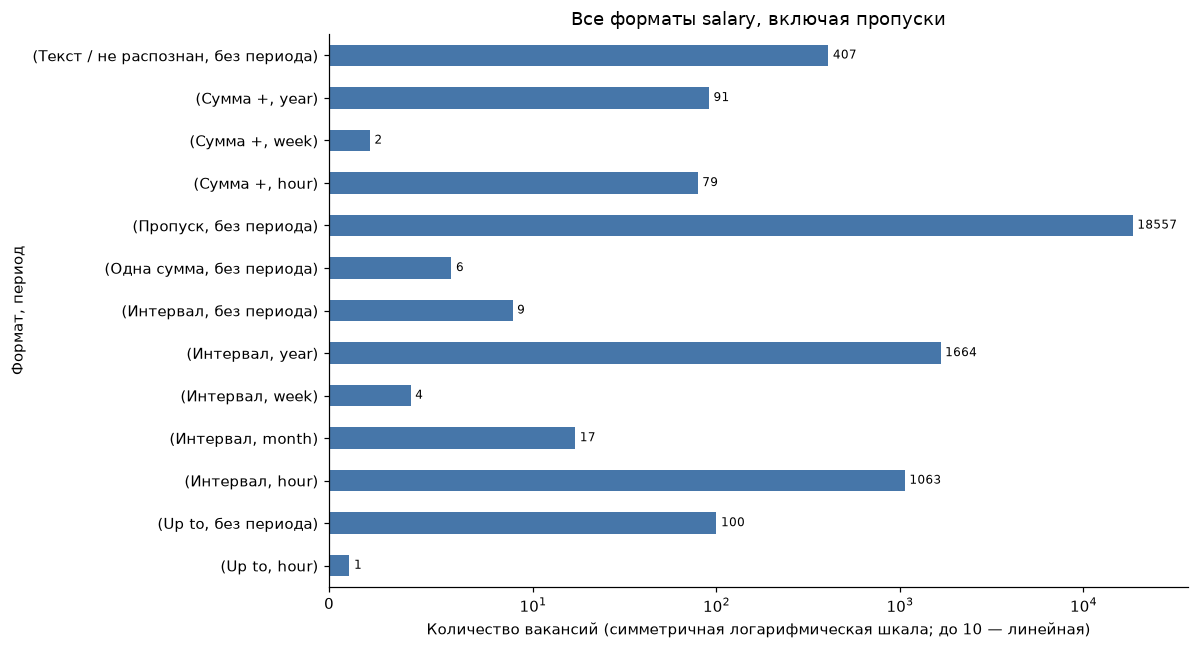

,salary,salary_min,salary_max,salary_period_observed,salary_format,salary_bound_kind,salary_note
12638,"$75,000.00+ /year",75000.00,NaN,year,Сумма +,at_least,None
3089,"45,000.00 - 60,000.00 $ /yearHealth Benefits",45000.00,60000.00,year,Интервал,range,Health Benefits
14707,28.55 - 28.55 $ /hour,28.55,28.55,hour,Интервал,range,None
1160,100.00 - 120.00 $ /hour,100.00,120.00,hour,Интервал,range,None
10589,"85,000.00 - 85,000.00 $ /year",85000.00,85000.00,year,Интервал,range,None
13507,"95,000.00 - 105,000.00 $ /year",95000.00,105000.00,year,Интервал,range,None
10220,15.40 - 15.40 $ /hourOvertime and Benefits,15.40,15.40,hour,Интервал,range,Overtime and Benefits
6079,24.23 - 29.86 $ /year,24.23,29.86,year,Интервал,range,None
19892,$12.00+ /hour,12.00,NaN,hour,Сумма +,at_least,None
12906,43.00 - 43.00 $ /hour,43.00,43.00,hour,Интервал,range,None


Непустых записей salary: 3443
Разобрано числовых зарплат: 3036
Текста без числовой зарплаты: 407


In [ ]:
salary_parsed = pd.DataFrame(df.salary.map(parse_salary).tolist(), index=df.index)
salary_parsed[["salary_min", "salary_max"]] = salary_parsed[["salary_min", "salary_max"]].astype(float)
salary_formats = salary_parsed.groupby(["salary_format", salary_parsed.salary_period_observed.fillna("без периода")]).size()
display(salary_formats.rename("Количество").to_frame())
ax = salary_formats.rename(index=lambda x: x).plot.barh(color="#4676a9", figsize=(11, 6))
ax.set(xlabel="Количество вакансий", ylabel="Формат, период", title="Все форматы salary, включая пропуски")
ax.bar_label(ax.containers[0], padding=3, fontsize=8)
ax.set_xscale("symlog", linthresh=10)
ax.set_xlabel("Количество вакансий (симметричная логарифмическая шкала; до 10 — линейная)")
ax.set_xlim(0, max(salary_formats) * 2)
plt.tight_layout()
plt.show()
display(pd.concat([df[["salary"]], salary_parsed], axis=1)
        .loc[salary_parsed.salary_min.notna()].sample(10, random_state=13))
print("Непустых записей salary:", int(df.salary.notna().sum()))
print("Разобрано числовых зарплат:", int(salary_parsed.salary_min.notna().sum()))
print("Текста без числовой зарплаты:", int((df.salary.notna() & salary_parsed.salary_min.isna()).sum()))

### 4.10. Границы зарплаты и статистика по периодам (задание 2.2)

Созданы числовые поля `salary_min`, `salary_max` типа `float64` и поле периода `salary_period_observed`. По условию задания одиночная сумма, включая `Up to`, записана в минимальную границу. Для каждого указанного периода рассчитаны среднее и медиана минимальной зарплаты; построена диаграмма с группировкой.

,count,mean,median,min,max
salary_period_observed,,,,,
hour,1143,187.46,15.14,0.0,100000.00
week,6,593.67,600.00,12.0,1100.00
month,17,6048.41,4905.22,1800.0,17688.94
year,1755,59789.88,55000.00,0.0,1000000.00


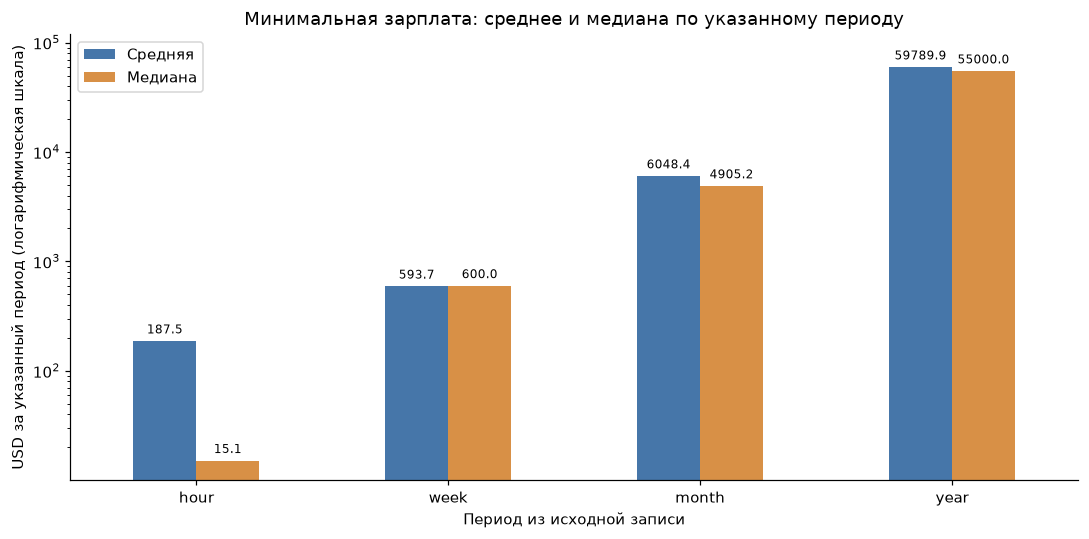

**Вывод:** средние и медианы различаются из-за выбросов и асимметрии распределений. Для восстановления периода использованы усечённые средние.

In [ ]:
PERIODS = ["hour", "week", "month", "year"]
observed_stats = (salary_parsed.dropna(subset=["salary_period_observed", "salary_min"])
                  .groupby("salary_period_observed").salary_min.agg(["count", "mean", "median", "min", "max"])
                  .reindex(PERIODS).dropna(how="all"))
display(observed_stats.round(2))
ax = observed_stats[["mean", "median"]].rename(columns={"mean": "Средняя", "median": "Медиана"}).plot.bar(
    color=["#4676a9", "#d89046"], rot=0, figsize=(10, 5))
ax.set(title="Минимальная зарплата: среднее и медиана по указанному периоду",
       xlabel="Период из исходной записи", ylabel="USD за указанный период (логарифмическая шкала)", yscale="log")
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3, fontsize=8)
ax.set_ylim(top=observed_stats[["mean", "median"]].to_numpy().max() * 2)
plt.tight_layout()
plt.show()
display(Markdown('**Вывод:** средние и медианы различаются из-за выбросов и асимметрии распределений. Для восстановления периода использованы усечённые средние.'))

### 4.11. Распределения и выбросы (задание 2.3)

Для каждого периода определён диапазон зарплат и построена гистограмма. Для восстановления периода использованы положительные ставки с известными единицами, кроме `Up to`. Допустимые границы рассчитаны как `Q1 − 1.5·IQR` и `Q3 + 1.5·IQR`, средние — после отсечения нижних и верхних 5% значений.

In [ ]:
def fit_period_rules(salaries):
    eligible = (salaries.salary_period_observed.notna() & salaries.salary_min.gt(0)
                & salaries.salary_bound_kind.ne("up_to"))
    rows = []
    for period, values in salaries.loc[eligible].groupby("salary_period_observed").salary_min:
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower = max(0.0, q1 - 1.5 * iqr)
        upper = q3 + 1.5 * iqr
        if len(values) < 4 or iqr == 0:
            lower, upper = values.min(), values.max()
        q05, q95 = values.quantile([0.05, 0.95])
        trimmed = values[values.between(q05, q95)]
        if trimmed.empty:
            trimmed = values
        rows.append({"period": period, "n": len(values), "mean_raw": values.mean(),
                     "mean_trimmed": trimmed.mean(), "median": values.median(),
                     "min": values.min(), "max": values.max(),
                     "lower": lower, "upper": upper,
                     "outside_fences": int((~values.between(lower, upper)).sum()),
                     "small_sample": len(values) < 10})
    return pd.DataFrame(rows).set_index("period").reindex([p for p in ["hour", "week", "month", "year"]
                                                          if p in {row['period'] for row in rows}])

def infer_period(amount, rules):
    if pd.isna(amount) or amount <= 0 or rules.empty:
        return None, "нет положительной суммы"
    distances = (rules.mean_trimmed - amount).abs().sort_values()
    if len(distances) > 1 and distances.iloc[1] <= distances.iloc[0] * 1.10 + 1e-9:
        return None, "неоднозначно: разница расстояний не более 10%"
    period = distances.index[0]
    rule = rules.loc[period]
    if not rule.lower <= amount <= rule.upper:
        return None, "вне допустимого диапазона ближайшей группы"
    if rule.small_sample:
        return None, "слишком мало наблюдений в ближайшей группе"
    return period, "по ближайшему усечённому среднему"

,n,mean_raw,mean_trimmed,median,min,max,lower,upper,outside_fences,small_sample
period,,,,,,,,,,
hour,1082,198.01,19.49,16.00,1.0,100000.00,0.0,42.00,85,False
week,6,593.67,612.50,600.00,12.0,1100.00,0.0,1743.75,0,True
month,17,6048.41,6313.93,4905.22,1800.0,17688.94,185.0,9489.00,2,False
year,1682,62384.80,60018.89,58000.00,1.0,1000000.00,0.0,140000.00,30,False


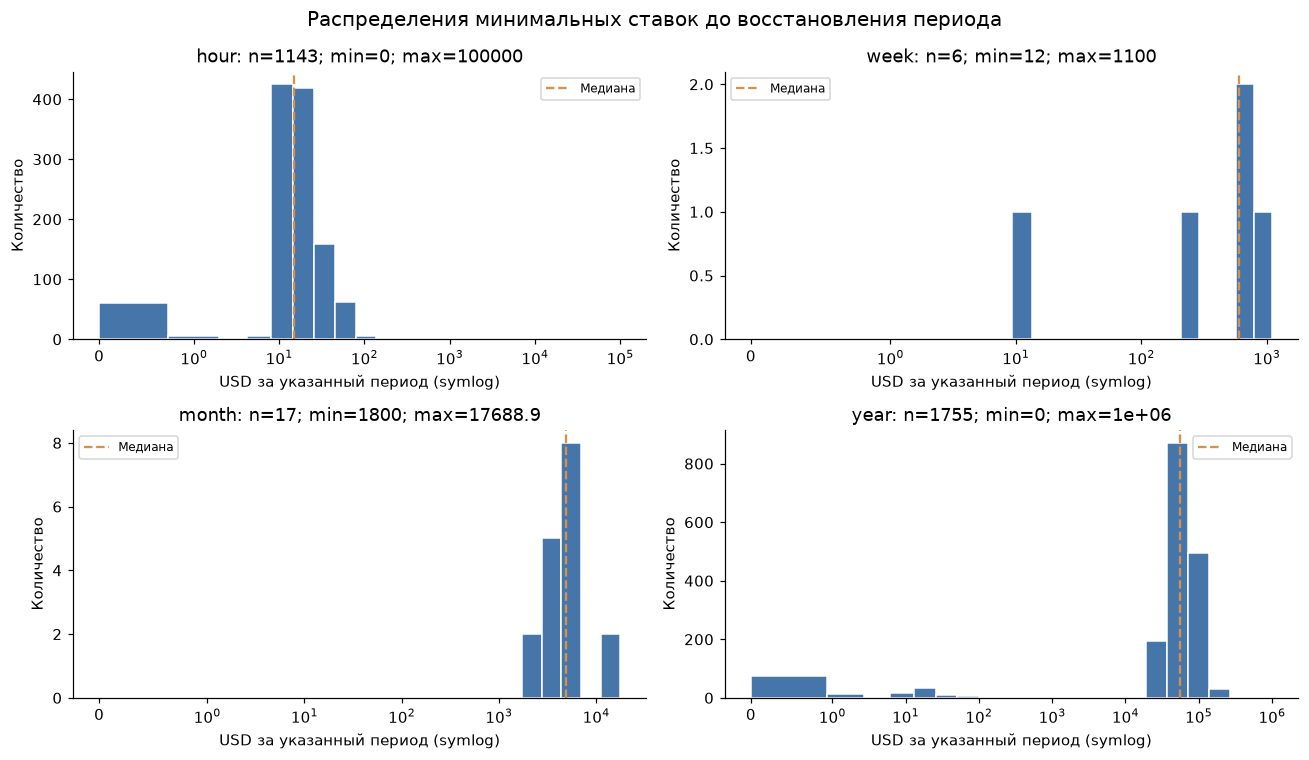

,salary,salary_min,salary_period_observed
30,62.00 - 81.00 $ /hour,62.0,hour
111,50.00 - 65.00 $ /hour,50.0,hour
136,45.00 - 50.00 $ /hour,45.0,hour
166,"0.00 - 85,000.00 $ /year",0.0,year
227,60.00 - 82.00 $ /hour,60.0,hour
401,0.00 - 20.00 $ /hour,0.0,hour
422,"0.00 - 90,000.00 $ /year",0.0,year
640,0.00 - 12.25 $ /hourPlus benefits,0.0,hour
748,55.00 - 65.00 $ /hour,55.0,hour
857,55.00 - 65.00 $ /hour,55.0,hour


**Вывод:** обнаружены нулевые и аномальные ставки. В недельной группе только 6 наблюдений, поэтому она не использована для заполнения периода.

In [ ]:
period_rules = fit_period_rules(salary_parsed)
display(period_rules.round(2))
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, period in zip(axes.flat, PERIODS):
    values = salary_parsed.loc[salary_parsed.salary_period_observed.eq(period), "salary_min"].dropna()
    if values.empty:
        ax.text(.5, .5, "Нет наблюдений", ha="center", transform=ax.transAxes)
        ax.set_title(period)
        continue

    top = max(float(values.max()), 1.0)
    bins = np.unique(np.r_[0.0, np.expm1(np.linspace(0, np.log1p(top), 22))])
    ax.hist(values, bins=bins, color="#4676a9", edgecolor="white")
    ax.set_xscale("symlog", linthresh=1)
    ax.set(title=f"{period}: n={len(values)}; min={values.min():g}; max={values.max():g}",
           xlabel="USD за указанный период (symlog)", ylabel="Количество")
    ax.axvline(values.median(), color="#d89046", linestyle="--", label="Медиана")
    ax.legend(fontsize=8)
fig.suptitle("Распределения минимальных ставок до восстановления периода", fontsize=13)
plt.tight_layout()
plt.show()
salary_outlier = pd.Series(False, index=df.index)
for period, rule in period_rules.iterrows():
    mask = salary_parsed.salary_period_observed.eq(period)
    salary_outlier.loc[mask] = (~salary_parsed.loc[mask, "salary_min"].between(rule.lower, rule.upper)
                               | salary_parsed.loc[mask, "salary_min"].le(0))
display(pd.concat([df[["salary"]], salary_parsed[["salary_min", "salary_period_observed"]]], axis=1)
        .loc[salary_outlier].head(10))
display(Markdown('**Вывод:** обнаружены нулевые и аномальные ставки. В недельной группе только 6 наблюдений, поэтому она не использована для заполнения периода.'))

### 4.12. Восстановление неизвестного периода (задание 2.3)

Для каждой суммы без периода выбрана группа с ближайшим усечённым средним. Период заполнен, если сумма входит в допустимый диапазон и в группе есть не менее 10 наблюдений. Если расстояния до двух ближайших средних различаются не более чем на 10%, период оставлен пустым. Восстановленные значения отмечены отдельно.

In [ ]:
salary_final = salary_parsed.copy()
salary_final["salary_period"] = salary_final.salary_period_observed.astype("string")
salary_final["salary_period_source"] = np.where(salary_final.salary_period.notna(), "из источника", "не определён")
salary_final["salary_period_reason"] = ""
unknown_period = salary_final.salary_min.notna() & salary_final.salary_period_observed.isna()
for idx in salary_final.index[unknown_period]:
    period, reason = infer_period(salary_final.at[idx, "salary_min"], period_rules)
    salary_final.at[idx, "salary_period_reason"] = reason
    if period:
        salary_final.at[idx, "salary_period"] = period
        salary_final.at[idx, "salary_period_source"] = "восстановлен"
display(pd.concat([df[["salary"]], salary_final[["salary_min", "salary_max", "salary_period",
                                               "salary_period_source", "salary_period_reason"]]], axis=1)
        .loc[unknown_period])
print("Числовых записей без периода до обработки:", int(unknown_period.sum()))
print("Периодов восстановлено:", int(salary_final.salary_period_source.eq("восстановлен").sum()))
print("Числовых записей без периода после:", int((salary_final.salary_min.notna() & salary_final.salary_period.isna()).sum()))
period_comparison = pd.DataFrame({"Период из источника": salary_final.salary_period_observed.value_counts(),
                                 "После восстановления": salary_final.salary_period.value_counts()}).fillna(0).astype(int)
display(period_comparison)
display(Markdown('**Вывод:** период восстановлен у 102 из 115 числовых записей без периода. У 13 записей он остался неизвестным.'))

,salary,salary_min,salary_max,salary_period,salary_period_source,salary_period_reason
42,Up to $32000.00,32000.0,NaN,<NA>,не определён,неоднозначно: разница расстояний не более 10%
154,Up to $45000.00,45000.0,NaN,year,восстановлен,по ближайшему усечённому среднему
2424,"108,887.00 - 141,555.00",108887.0,141555.0,year,восстановлен,по ближайшему усечённому среднему
2630,Up to $18.00,18.0,NaN,hour,восстановлен,по ближайшему усечённому среднему
2639,Up to $13.00,13.0,NaN,hour,восстановлен,по ближайшему усечённому среднему
...,...,...,...,...,...,...
18289,12.50,12.5,NaN,hour,восстановлен,по ближайшему усечённому среднему
20014,Up to $14.00,14.0,NaN,hour,восстановлен,по ближайшему усечённому среднему
21168,Up to $20.00,20.0,NaN,hour,восстановлен,по ближайшему усечённому среднему
21270,Up to $31500.00,31500.0,NaN,<NA>,не определён,вне допустимого диапазона ближайшей группы


Числовых записей без периода до обработки: 115
Периодов восстановлено: 102
Числовых записей без периода после: 13


,Период из источника,После восстановления
hour,1143,1206
month,17,17
week,6,6
year,1755,1794


**Вывод:** период восстановлен у 102 из 115 числовых записей без периода. У 13 записей он остался неизвестным.

### 4.13. Стандартизация занятости (задание 3)

В `job_type` нормализованы пробелы, разделители и регистр. Выделены полнота и тип занятости. Отсутствующие компоненты заполнены значениями `Full Time` и `Employee`; подстановки отмечены флагами. Построена диаграмма с накоплением.

In [ ]:
FULLNESS = re.compile(r"\b(full\s*time|part\s*time|per\s*diem)\b", re.I)
CONTRACT = re.compile(r"\b(temporary\s*/\s*contract\s*/\s*project|employee|intern|seasonal)\b", re.I)

def normalize_job_type(value):
    text = compact(value)
    text = re.sub(r"^job\s+type\s*:?\s*", "", text, flags=re.I)
    text = re.sub(r"temporary\s*/\s*contract\s*/\s*project", "Temporary/Contract/Project", text, flags=re.I)
    text = re.sub(r"\b(full\s*time|part\s*time|per\s*diem|employee|intern|seasonal)\b",
                  lambda m: {"fulltime": "Full Time", "parttime": "Part Time", "perdiem": "Per Diem",
                             "employee": "Employee", "intern": "Intern", "seasonal": "Seasonal"}
                  [re.sub(r"\s+", "", m[0]).lower()], text, flags=re.I)

    text = text.replace("Temporary/Contract/Project", "__CONTRACT__")
    text = re.sub(r"[\s,/>]+", " ", text).strip()
    return text.replace("__CONTRACT__", "Temporary/Contract/Project")

def parse_job_type(value):
    text = normalize_job_type(value)
    f, t = FULLNESS.search(text), CONTRACT.search(text)
    fullness = f[0] if f else "Full Time"
    contract = t[0] if t else "Employee"
    remainder = CONTRACT.sub("", FULLNESS.sub("", text)).strip(" ,/>")
    return {"job_type_normalized": text or None, "employment_fullness": fullness,
            "employment_type": contract, "fullness_defaulted": f is None,
            "employment_type_defaulted": t is None, "job_type_unrecognized": remainder or None}

Все исходные форматы job_type:


,Количество
job_type,
Full Time,6757
Full Time Employee,6617
"Full Time, Employee",3360
<пропуск>,1628
Full Time Temporary/Contract/Project,1062
"Full Time, Temporary/Contract/Project",533
"Full Time , Employee",406
Part Time Employee,382
Part Time,329


,Исходная запись,После нормализации,Количество
0,Full Time,Full Time,6757
1,Full Time Employee,Full Time Employee,6617
2,"Full Time, Employee",Full Time Employee,3360
3,<пропуск>,<пропуск>,1628
4,Full Time Temporary/Contract/Project,Full Time Temporary/Contract/Project,1062
5,"Full Time, Temporary/Contract/Project",Full Time Temporary/Contract/Project,533
6,"Full Time , Employee",Full Time Employee,406
7,Part Time Employee,Part Time Employee,382
8,Part Time,Part Time,329
9,"Part Time, Employee",Part Time Employee,196


Уникальных непустых записей до: 39 после нормализации: 15
Полнота заполнена значением по умолчанию: 1970
Тип заполнен значением по умолчанию: 8754


,job_type,job_type_normalized,employment_fullness,employment_type,fullness_defaulted,employment_type_defaulted,job_type_unrecognized
5439,Exempt,Exempt,Full Time,Employee,True,True,Exempt


employment_type,Employee,Intern,Seasonal,Temporary/Contract/Project
employment_fullness,,,,
Full Time,19088,5,0,1847
Part Time,916,3,17,57
Per Diem,63,0,0,4


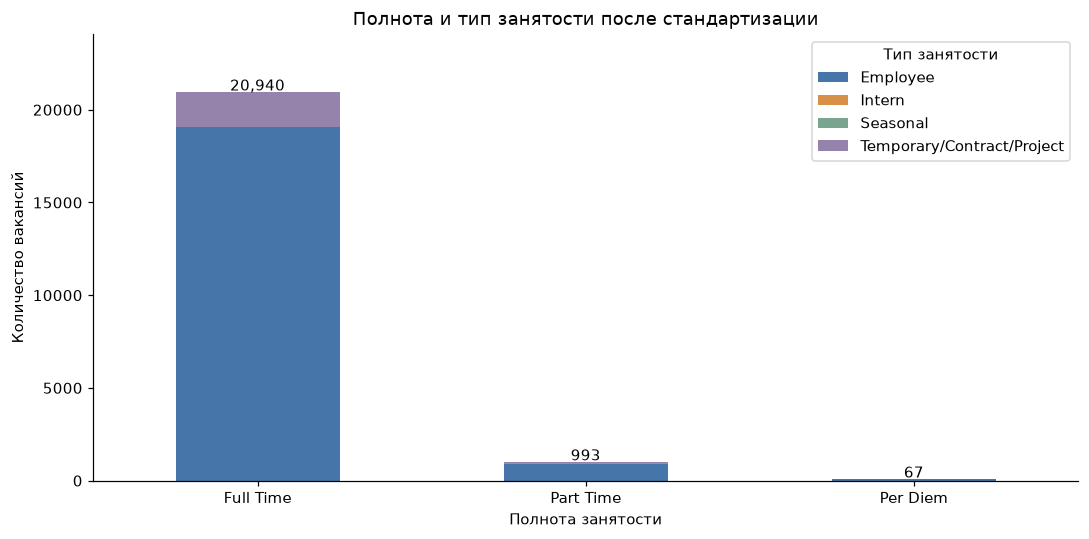

**Вывод:** преобладает полная занятость Employee. Полнота заполнена по условию у 1 970 записей, тип — у 8 754.

In [ ]:
print("Все исходные форматы job_type:")
display(df.job_type.fillna("<пропуск>").value_counts().rename("Количество").to_frame())
job_parsed = pd.DataFrame(df.job_type.map(parse_job_type).tolist(), index=df.index)
normalization_map = pd.DataFrame({"Исходная запись": df.job_type.fillna("<пропуск>"),
                                  "После нормализации": job_parsed.job_type_normalized.fillna("<пропуск>")})
display(normalization_map.value_counts().rename("Количество").to_frame().reset_index())
print("Уникальных непустых записей до:", df.job_type.nunique(),
      "после нормализации:", job_parsed.job_type_normalized.nunique())
print("Полнота заполнена значением по умолчанию:", int(job_parsed.fullness_defaulted.sum()))
print("Тип заполнен значением по умолчанию:", int(job_parsed.employment_type_defaulted.sum()))
display(pd.concat([df[["job_type"]], job_parsed], axis=1)
        .loc[job_parsed.job_type_unrecognized.notna()])
employment_table = pd.crosstab(job_parsed.employment_fullness, job_parsed.employment_type)
employment_table = employment_table.reindex(["Full Time", "Part Time", "Per Diem"], fill_value=0)
display(employment_table)
ax = employment_table.plot.bar(stacked=True, rot=0, figsize=(10, 5),
                               color=["#4676a9", "#d89046", "#79a48e", "#9683ac"])
ax.set(title="Полнота и тип занятости после стандартизации", xlabel="Полнота занятости", ylabel="Количество вакансий")
ax.legend(title="Тип занятости", loc="upper right")
for idx, total in enumerate(employment_table.sum(axis=1)):
    ax.text(idx, total + 100, f"{total:,}", ha="center")
ax.set_ylim(0, employment_table.sum(axis=1).max() * 1.15)
plt.tight_layout()
plt.show()
display(Markdown('**Вывод:** преобладает полная занятость Employee. Полнота заполнена по условию у 1 970 записей, тип — у 8 754.'))

## 5. Результаты

Исходные данные и новые признаки объединены в таблицу из 22 000 строк и 35 столбцов. Обработанная таблица, отложенные адреса и сводные показатели сохранены в CSV-файлы в папке `results/`.

In [ ]:
cleaned = pd.concat([df, location_final, salary_final, job_parsed], axis=1)
cleaned["salary_outlier_observed"] = salary_outlier
cleaned["duplicate_content"] = duplicate_extra
assert len(cleaned) == len(df)
pd.testing.assert_frame_equal(cleaned[df.columns], df)
assert cleaned.uniq_id.equals(df.uniq_id)
assert cleaned.postal_code.dropna().str.fullmatch(ZIP).all()
assert set(cleaned.state_code.dropna()) <= set(STATE_NAMES)
assert cleaned.loc[cleaned.salary_max.notna(), "salary_min"].le(cleaned.salary_max.dropna()).all()
assert cleaned[["salary_min", "salary_max"]].dtypes.eq("float64").all()
observed = salary_parsed.salary_period_observed.notna()
assert (cleaned.loc[observed, "salary_period"] == salary_parsed.loc[observed, "salary_period_observed"]).all()
assert cleaned[["employment_fullness", "employment_type"]].notna().all().all()
assert employment_table.to_numpy().sum() == len(df)
assert location_counts.sum() == len(df)
assert salary_formats.sum() == len(df)

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
cleaned.to_csv(RESULTS / "monster_jobs_cleaned.csv", index=False)
deferred_locations.to_csv(RESULTS / "location_deferred.csv", index=False)
unresolved = cleaned[["city", "state_code", "postal_code"]].isna().all(axis=1)
cleaned.loc[unresolved].to_csv(RESULTS / "location_unresolved.csv", index=False)
missing_table.to_csv(RESULTS / "missing_values.csv")
period_rules.to_csv(RESULTS / "salary_period_rules.csv")
summary = pd.DataFrame({"Показатель": ["Исходных строк", "Итоговых строк", "Исходных столбцов", "Итоговых столбцов",
    "Избыточных повторов содержания", "Извлечён город", "Извлечён штат", "Извлечён ZIP",
    "Адрес полностью неизвестен", "Распознана числовая зарплата", "Период указан в источнике",
    "Период восстановлен", "Числовая зарплата без периода после обработки",
    "Полнота занятости заполнена по условию", "Тип занятости заполнен по условию"],
    "Значение": [len(df), len(cleaned), len(df.columns), len(cleaned.columns), int(duplicate_extra.sum()),
    int(cleaned.city.notna().sum()), int(cleaned.state_code.notna().sum()), int(cleaned.postal_code.notna().sum()),
    int(unresolved.sum()), int(cleaned.salary_min.notna().sum()), int(observed.sum()),
    int(cleaned.salary_period_source.eq("восстановлен").sum()),
    int((cleaned.salary_min.notna() & cleaned.salary_period.isna()).sum()),
    int(cleaned.fullness_defaulted.sum()), int(cleaned.employment_type_defaulted.sum())]})
display(summary)
summary.to_csv(RESULTS / "summary.csv", index=False)
print("Проверки данных пройдены. Созданы файлы:")
for path in sorted(RESULTS.glob("*.csv")):
    print(path.as_posix(), f"({path.stat().st_size:,} байт)")

,Показатель,Значение
0,Исходных строк,22000
1,Итоговых строк,22000
2,Исходных столбцов,14
3,Итоговых столбцов,35
4,Избыточных повторов содержания,1168
5,Извлечён город,19649
6,Извлечён штат,19633
7,Извлечён ZIP,12287
8,Адрес полностью неизвестен,1763
9,Распознана числовая зарплата,3036


Проверки данных пройдены. Созданы файлы:
results/location_deferred.csv (10,969,133 байт)
results/location_unresolved.csv (7,669,913 байт)
results/missing_values.csv (404 байт)
results/monster_jobs_cleaned.csv (71,665,493 байт)
results/salary_period_rules.csv (416 байт)
results/summary.csv (799 байт)


## 6. Выводы по проделанной работе

Исследованы пропуски, константные поля, несоответствия содержимого названиям столбцов и дубликаты. Удаление всех неполных строк оставляло только 5 вакансий, поэтому обработка выполнена с сохранением всех 22 000 записей. Найдено 1 168 избыточных повторов содержания.

Местоположение разделено на город, штат и почтовый индекс. Город извлечён у 19 649 записей, штат — у 19 633, ZIP — у 12 287. Неоднозначные и неизвестные компоненты оставлены пустыми.

Числовая зарплата распознана у 3 036 записей. Для разных периодов рассчитаны средние, медианы и диапазоны, построены гистограммы. Из 115 записей с неизвестным периодом он восстановлен у 102, у 13 оставлен пустым.

Значения `job_type` приведены к единому формату и разделены на полноту и тип занятости. Пропущенные компоненты заполнены по условию задания. Полученная таблица позволяет анализировать вакансии по местоположению, зарплате и занятости.